In [ ]:
import fiftyone as fo




In [1]:
import torch
import torch.nn as nn

# A simple 2-layer model
class MiniNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(2, 3)
        self.fc2 = nn.Linear(3, 1)

    def forward(self, x):
        h = self.fc1(x)        # Intermediate activation (non-leaf)
        a = torch.relu(h)      # Intermediate activation (non-leaf)
        out = self.fc2(a)      # Intermediate activation (non-leaf)
        return out, a

model = MiniNet()
x = torch.tensor([[1.0, 2.0]]) # Input data

# Run forward pass
out, a = model(x)
loss = out.sum()

# Run backward pass
loss.backward()

# 1. PARAMETERS (Leaf Tensors) -> Keep their gradients so the optimizer can update them!
print("fc1.weight.grad:", model.fc1.weight.grad) # Stores tensor of shape [3, 2]
print("fc2.weight.grad:", model.fc2.weight.grad) # Stores tensor of shape [1, 3]

# 2. INTERMEDIATE ACTIVATIONS (Non-Leaf) -> Gradients are discarded to save VRAM
print("a.grad:", a.grad)                         # None

fc1.weight.grad: tensor([[ 0.0000,  0.0000],
        [-0.3109, -0.6217],
        [ 0.2072,  0.4144]])
fc2.weight.grad: tensor([[0.0000, 0.7817, 1.0596]])
a.grad: None


/tmp/ipykernel_12780/1930295656.py:32: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more information. (Triggered internally at /pytorch/build/aten/src/ATen/core/TensorBody.h:494.)
  print("a.grad:", a.grad)                         # None


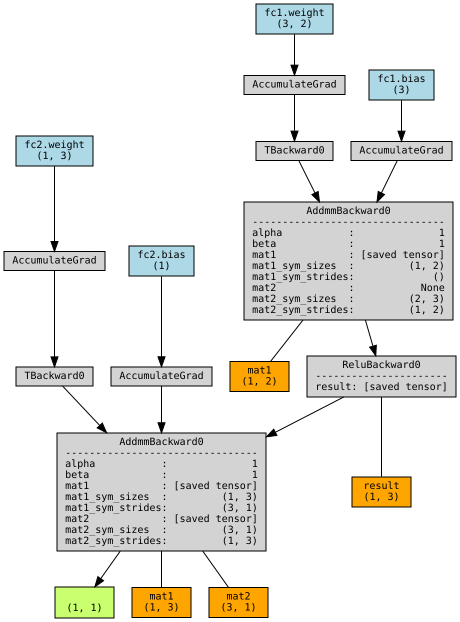

In [8]:
import torch
import torch.nn as nn
from torchviz import make_dot

# 1. Define model and input
class MiniNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(2, 3)
        self.fc2 = nn.Linear(3, 1)

    def forward(self, x):
        h = self.fc1(x)
        a = torch.relu(h)
        return self.fc2(a)

model = MiniNet()
x = torch.tensor([[1.0, 2.0]])

# 2. Forward pass
out = model(x)

# 3. Render directly in Jupyter (just leave 'make_dot' as the last line)
make_dot(out, params=dict(model.named_parameters()), show_attrs=True, show_saved=True)

In [14]:
def print_autograd_graph(grad_fn, indent=0):
    if grad_fn is None:
        return
    
    # Print current operation node name
    prefix = "  " * indent
    print(f"{prefix}├── Function: {type(grad_fn).__name__}")
    
    # Print saved tensors cached inside the grad_fn if available
    if hasattr(grad_fn, "_saved_self"):
        print(f"{prefix}│   └── Saved Self Shape: {grad_fn._saved_self.shape}")
    
    # Traverse child nodes (next operations in backward pass)
    if hasattr(grad_fn, "next_functions"):
        for next_fn, _ in grad_fn.next_functions:
            if next_fn is not None:
                print_autograd_graph(next_fn, indent + 1)

# Pass the output tensor's grad_fn
print("--- Computational Graph Tree ---")
print_autograd_graph(out.grad_fn)

--- Computational Graph Tree ---
├── Function: AddmmBackward0
  ├── Function: AccumulateGrad
  ├── Function: ReluBackward0
    ├── Function: AddmmBackward0
      ├── Function: AccumulateGrad
      ├── Function: TBackward0
        ├── Function: AccumulateGrad
  ├── Function: TBackward0
    ├── Function: AccumulateGrad


In [18]:
import torch
import torch.nn as nn

class MiniNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(2, 3)
        self.fc2 = nn.Linear(3, 1)

    def forward(self, x):
        h = self.fc1(x)
        a = torch.relu(h)
        
        # Register a hook on the intermediate tensor 'a'
        a.register_hook(lambda grad: print("Gradient passing through ReLU (a.grad):", grad))
        
        return self.fc2(a), a

model = MiniNet()
x = torch.tensor([[1.0, 2.0]])

# Forward pass
out, a = model(x)
print("Saved Forward Activation 'a':", a)

# Backward pass (triggers the hook print)
out.sum().backward()

Saved Forward Activation 'a': tensor([[0.1628, 0.2203, 0.0000]], grad_fn=<ReluBackward0>)
Gradient passing through ReLU (a.grad): tensor([[ 0.3320, -0.0127,  0.4960]])
